# D2→D3 TDI/IAG selected-program heatmap on the CLR scale

This notebook recomputes small-molecule program effects from the saved zero-based projected AnnData object.

Workflow:

1. apply the same cell QC filters used previously;
2. apply a log2 CLR transform to each cell's 50-program usage composition;
3. average CLR scores within each biological sample;
4. calculate matched replicate effects for D2→D3 TDI and IAG relative to D3 control;
5. run paired tests across biological replicates;
6. BH-adjust across the 8 treatment × program tests;
7. draw a 3 × 4 square-cell heatmap with a white control/control reference row.

The control row is a constructed zero reference and is not assigned a p-value or significance star.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import scanpy as sc
from scipy.stats import ttest_1samp
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 9,
    "figure.dpi": 160,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",  # editable text in Illustrator
})

BASE = Path("/scratch/users/edtng/20260325_Hippo_timecourse")
H5AD_PATH = (
    BASE / "perturbseq_cNMF_projection" /
    "Hippo_timecourse_combined.projected_perturbseq_cNMF_50_dt_0_2.zero_based.h5ad"
)
OUT_DIR = BASE / "perturbseq_cNMF_projection" / "D2toD3_CLR_selected_program_heatmap"
OUT_DIR.mkdir(parents=True, exist_ok=True)

SCORE_KEY = "X_perturbseq_cNMF_usage"
SAMPLE_COL = "sample_name"

# Figure order, matching the example figure.
PROGRAMS = ["P34", "P27", "P24", "P2"]
PROGRAM_LABELS = {
    "P34": "P34\nYAP/TAZ\nmesenchyme",
    "P27": "P27\nalt.",
    "P24": "P24\nmesenchymal",
    "P2": "P2\narterial EC",
}

CONTROL_CONDITION = "D3_AE"
TREATED_CONDITIONS = {
    "TDI": "D2_LM+TDI->D3_AE+TDI",
    "IAG": "D2_LM+IAG->D3_AE+IAG",
}
ROW_ORDER = ["Control", "TDI", "IAG"]

# Match the programDE CLR scale as closely as possible.
# Set this to the exact epsilon used in the programDE run if it differed.
CLR_EPS = 1e-6
CLR_LOG_BASE = 2

# Stars default to BH-adjusted q-values across the 8 treatment × program tests.
# Change to "pvalue" only if you explicitly want unadjusted paired-test stars.
STAR_SOURCE = "qvalue"

print("H5AD:", H5AD_PATH, H5AD_PATH.exists())
print("Output:", OUT_DIR)

H5AD: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/Hippo_timecourse_combined.projected_perturbseq_cNMF_50_dt_0_2.zero_based.h5ad True
Output: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/D2toD3_CLR_selected_program_heatmap


In [2]:
# Same condition-specific QC cutoffs used in the preceding time-course analyses.
cond_pct_ribo_cutoffs = {
    'D0_hPSC': 2.4,
    'D1_MPS': 2.3,
    'D1_MPS+TDI': 2.5,
    'D1_MPS+IAG': 2.2,
    'D1.33_LM': 1.9,
    'D1.33_LM+TDI': 2.1,
    'D1.33_LM+IAG': 2.2,
    'D1.67_LM': 2.0,
    'D1.67_LM+TDI': 2.2,
    'D1.67_LM+IAG': 1.9,
    'D2_LM': 2.0,
    'D2_LM+TDI': 2.4,
    'D2_LM+IAG': 1.9,
    'D3_AE': 1.0,
    'D3_AE+TDI': 2.0,
    'D3_AE+IAG': 1.0,
    'D2_LM+TDI->D3_AE+TDI': 2.5,
    'D2_LM+IAG->D3_AE+IAG': 1.0,
}

cond_pct_mt_cutoffs = {
    'D0_hPSC': 5.5,
    'D1_MPS': 3.0,
    'D1_MPS+TDI': 3.0,
    'D1_MPS+IAG': 4,
    'D1.33_LM': 3.5,
    'D1.33_LM+TDI': 3.75,
    'D1.33_LM+IAG': 5,
    'D1.67_LM': 4.0,
    'D1.67_LM+TDI': 5.5,
    'D1.67_LM+IAG': 3.5,
    'D2_LM': 6.5,
    'D2_LM+TDI': 8,
    'D2_LM+IAG': 3.5,
    'D3_AE': 3.25,
    'D3_AE+TDI': 7.0,
    'D3_AE+IAG': 3.75,
    'D2_LM+TDI->D3_AE+TDI': 7,
    'D2_LM+IAG->D3_AE+IAG': 3.75,
}


def parse_sample_name(sample_name):
    sample_name = str(sample_name)
    m = re.match(r"^(.*)_rep(\d+)$", sample_name)
    if m is None:
        raise ValueError(f"Could not parse condition/replicate from {sample_name!r}")
    return m.group(1), f"rep{m.group(2)}"


def clr_transform_rows(usage, eps=1e-6, log_base=2):
    """Floor, renormalize, and CLR-transform rows of a cells × programs matrix."""
    usage = np.asarray(usage, dtype=np.float64)
    if usage.ndim != 2:
        raise ValueError("usage must be 2D")
    if np.any(usage < 0):
        raise ValueError("usage contains negative values")

    row_sums = usage.sum(axis=1, keepdims=True)
    usage = np.divide(usage, row_sums, out=np.zeros_like(usage), where=row_sums > 0)
    floored = np.maximum(usage, eps)
    floored = floored / floored.sum(axis=1, keepdims=True)

    if log_base == 2:
        log_u = np.log2(floored)
    elif log_base == "natural":
        log_u = np.log(floored)
    else:
        raise ValueError("log_base must be 2 or 'natural'")

    clr = log_u - log_u.mean(axis=1, keepdims=True)
    return clr.astype(np.float32)


def bh_adjust(pvalues):
    pvalues = np.asarray(pvalues, dtype=float)
    qvalues = np.full_like(pvalues, np.nan, dtype=float)
    mask = np.isfinite(pvalues)
    p = pvalues[mask]
    if p.size == 0:
        return qvalues
    order = np.argsort(p)
    ranked = p[order]
    n = ranked.size
    adj = ranked * n / np.arange(1, n + 1)
    adj = np.minimum.accumulate(adj[::-1])[::-1]
    adj = np.clip(adj, 0, 1)
    restored = np.empty_like(adj)
    restored[order] = adj
    qvalues[mask] = restored
    return qvalues


def significance_stars(value):
    if not np.isfinite(value):
        return ""
    if value < 0.001:
        return "***"
    if value < 0.01:
        return "**"
    if value < 0.05:
        return "*"
    return ""

In [3]:
# Load only obs + obsm from the large object.
adata = sc.read_h5ad(H5AD_PATH, backed="r")
obs = adata.obs.copy()
usage = np.asarray(adata.obsm[SCORE_KEY])

projection_meta = adata.uns.get("perturbseq_cNMF_projection", {})
program_names = [str(x) for x in projection_meta.get("program_names", [])]
if len(program_names) != usage.shape[1]:
    program_names = [f"P{i}" for i in range(usage.shape[1])]

program_to_col = {p: i for i, p in enumerate(program_names)}
missing_programs = [p for p in PROGRAMS if p not in program_to_col]
if missing_programs:
    raise ValueError(f"Missing selected programs: {missing_programs}")

parsed = obs[SAMPLE_COL].astype(str).map(parse_sample_name)
obs["condition_qc"] = [x[0] for x in parsed]
obs["replicate_qc"] = [x[1] for x in parsed]

for col in ["pct_counts_mt", "pct_counts_ribo"]:
    obs[col] = pd.to_numeric(obs[col], errors="coerce")

# Apply condition-specific QC filter.
keep = np.ones(obs.shape[0], dtype=bool)
filter_records = []
for cond in obs["condition_qc"].unique():
    cond = str(cond)
    if cond not in cond_pct_mt_cutoffs or cond not in cond_pct_ribo_cutoffs:
        raise ValueError(f"No QC cutoff specified for {cond!r}")
    cond_mask = obs["condition_qc"].to_numpy() == cond
    fail_mt = cond_mask & (obs["pct_counts_mt"].to_numpy() >= cond_pct_mt_cutoffs[cond])
    fail_ribo = cond_mask & (obs["pct_counts_ribo"].to_numpy() <= cond_pct_ribo_cutoffs[cond])
    fail = fail_mt | fail_ribo
    keep &= ~fail
    filter_records.append({
        "condition": cond,
        "n_before": int(cond_mask.sum()),
        "n_removed": int(fail.sum()),
        "n_after": int(cond_mask.sum() - fail.sum()),
    })

filter_summary = pd.DataFrame(filter_records)
filter_summary.to_csv(OUT_DIR / "QC_filter_summary.tsv", sep="\t", index=False)

obs_f = obs.loc[keep].copy()
usage_f = usage[keep, :]
clr_f = clr_transform_rows(usage_f, eps=CLR_EPS, log_base=CLR_LOG_BASE)

print("Cells before QC:", obs.shape[0])
print("Cells after QC:", obs_f.shape[0])
print("CLR row mean range:", float(clr_f.mean(axis=1).min()), float(clr_f.mean(axis=1).max()))

# Sample-level mean CLR values across all programs.
sample_records = []
for sample_name in obs_f[SAMPLE_COL].astype(str).drop_duplicates():
    mask = obs_f[SAMPLE_COL].astype(str).to_numpy() == sample_name
    condition, replicate = parse_sample_name(sample_name)
    means = clr_f[mask, :].mean(axis=0)
    rec = {
        "sample_name": sample_name,
        "condition": condition,
        "replicate": replicate,
        "n_cells": int(mask.sum()),
    }
    rec.update({p: float(means[j]) for j, p in enumerate(program_names)})
    sample_records.append(rec)

sample_clr = pd.DataFrame(sample_records)
sample_clr.to_csv(OUT_DIR / "sample_mean_cell_level_CLR_usage.tsv", sep="\t", index=False)
display(sample_clr[["sample_name", "condition", "replicate", "n_cells"] + PROGRAMS])

adata.file.close()

Cells before QC: 212891
Cells after QC: 99416
CLR row mean range: -3.623962356869015e-07 3.623962356869015e-07


,sample_name,condition,replicate,n_cells,P34,P27,P24,P2
0,D2_LM+IAG_rep2,D2_LM+IAG,rep2,2601,-1.575960,-1.575960,-1.575960,-1.575960
1,D2_LM_rep1,D2_LM,rep1,2909,-1.558914,-1.558914,-1.529277,-1.558914
2,D2_LM+IAG_rep1,D2_LM+IAG,rep1,2621,-1.676567,-1.676567,-1.666542,-1.676567
3,D2_LM+TDI->D3_AE+TDI_rep1,D2_LM+TDI->D3_AE+TDI,rep1,3304,-0.901630,-0.860135,1.274557,-1.519057
4,D0_hPSC_rep1,D0_hPSC,rep1,2884,-2.438244,-2.438244,-2.428176,-2.438244
5,D2_LM_rep3,D2_LM,rep3,3381,-1.722660,-1.883417,-1.405238,-1.872705
6,D1.33_LM_rep2,D1.33_LM,rep2,1837,-2.143743,-2.135101,-1.818379,-2.143743
7,D0_hPSC_rep2,D0_hPSC,rep2,3317,-2.812102,-2.819703,-1.092591,-2.819703
8,D1.33_LM+TDI_rep2,D1.33_LM+TDI,rep2,1728,-1.964382,-2.454195,-2.192325,-2.460422
9,D1_MPS+IAG_rep3,D1_MPS+IAG,rep3,2355,-2.754256,-2.759434,-2.675478,-2.759434


In [4]:
# Matched replicate CLR effects and paired tests.
sample_index = sample_clr.set_index(["condition", "replicate"])
records = []
paired_records = []

for treatment, treated_condition in TREATED_CONDITIONS.items():
    control_reps = set(sample_clr.loc[sample_clr["condition"] == CONTROL_CONDITION, "replicate"])
    treated_reps = set(sample_clr.loc[sample_clr["condition"] == treated_condition, "replicate"])
    matched_reps = sorted(control_reps & treated_reps)
    if len(matched_reps) < 2:
        raise ValueError(f"Only {len(matched_reps)} matched replicates for {treatment}")

    for program in PROGRAMS:
        control_values = np.array([
            sample_index.loc[(CONTROL_CONDITION, rep), program] for rep in matched_reps
        ], dtype=float)
        treated_values = np.array([
            sample_index.loc[(treated_condition, rep), program] for rep in matched_reps
        ], dtype=float)
        differences = treated_values - control_values

        test = ttest_1samp(differences, popmean=0.0, nan_policy="omit")
        records.append({
            "row": treatment,
            "treated_condition": treated_condition,
            "control_condition": CONTROL_CONDITION,
            "program": program,
            "n_matched_pairs": len(matched_reps),
            "mean_control_clr": float(control_values.mean()),
            "mean_treated_clr": float(treated_values.mean()),
            "mean_diff_clr": float(differences.mean()),
            "sd_diff_clr": float(differences.std(ddof=1)) if len(differences) > 1 else np.nan,
            "paired_t_statistic": float(test.statistic),
            "pvalue": float(test.pvalue),
            "n_positive_diffs": int((differences > 0).sum()),
            "n_negative_diffs": int((differences < 0).sum()),
        })

        for rep, c, t, d in zip(matched_reps, control_values, treated_values, differences):
            paired_records.append({
                "row": treatment,
                "program": program,
                "replicate": rep,
                "control_clr": c,
                "treated_clr": t,
                "paired_diff_clr": d,
            })

effects = pd.DataFrame(records)
effects["qvalue_BH_8tests"] = bh_adjust(effects["pvalue"].to_numpy())
paired_effects = pd.DataFrame(paired_records)

effects.to_csv(OUT_DIR / "D2toD3_CLR_selected_program_effects_source.tsv", sep="\t", index=False)
paired_effects.to_csv(OUT_DIR / "D2toD3_CLR_selected_program_paired_replicate_values.tsv", sep="\t", index=False)

display(effects)
display(paired_effects)

,row,treated_condition,control_condition,program,n_matched_pairs,mean_control_clr,mean_treated_clr,mean_diff_clr,sd_diff_clr,paired_t_statistic,pvalue,n_positive_diffs,n_negative_diffs,qvalue_BH_8tests
0,TDI,D2_LM+TDI->D3_AE+TDI,D3_AE,P34,3,-1.585381,-0.700551,0.884830,0.391612,3.913490,0.059524,3,0,0.257414
1,TDI,D2_LM+TDI->D3_AE+TDI,D3_AE,P27,3,-1.632947,-0.110842,1.522105,0.915052,2.881109,0.102314,3,0,0.257414
2,TDI,D2_LM+TDI->D3_AE+TDI,D3_AE,P24,3,-1.536123,7.934259,9.470383,6.533122,2.510773,0.128707,3,0,0.257414
3,TDI,D2_LM+TDI->D3_AE+TDI,D3_AE,P2,3,-0.476531,-1.778701,-1.302171,1.248254,-1.806865,0.212526,1,2,0.340041
4,IAG,D2_LM+IAG->D3_AE+IAG,D3_AE,P34,3,-1.585381,-1.447726,0.137655,0.206417,1.155068,0.367424,3,0,0.436902
5,IAG,D2_LM+IAG->D3_AE+IAG,D3_AE,P27,3,-1.632947,-1.447726,0.185222,0.288801,1.110846,0.382289,3,0,0.436902
6,IAG,D2_LM+IAG->D3_AE+IAG,D3_AE,P24,3,-1.536123,-1.420672,0.115451,0.364771,0.548201,0.638568,1,2,0.638568
7,IAG,D2_LM+IAG->D3_AE+IAG,D3_AE,P2,3,-0.476531,1.167482,1.644013,1.114747,2.554404,0.125131,3,0,0.257414


,row,program,replicate,control_clr,treated_clr,paired_diff_clr
0,TDI,P34,rep1,-1.358960,-0.901630,0.457330
1,TDI,P34,rep2,-1.330704,-0.104481,1.226223
2,TDI,P34,rep3,-2.066478,-1.095541,0.970937
3,TDI,P27,rep1,-1.358960,-0.860135,0.498825
4,TDI,P27,rep2,-1.330704,0.931059,2.261763
5,TDI,P27,rep3,-2.209179,-0.403450,1.805729
6,TDI,P24,rep1,-1.160732,1.274557,2.435289
7,TDI,P24,rep2,-1.314249,9.315235,10.629484
8,TDI,P24,rep3,-2.133390,13.212986,15.346376
9,TDI,P2,rep1,0.638611,-1.519057,-2.157668


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

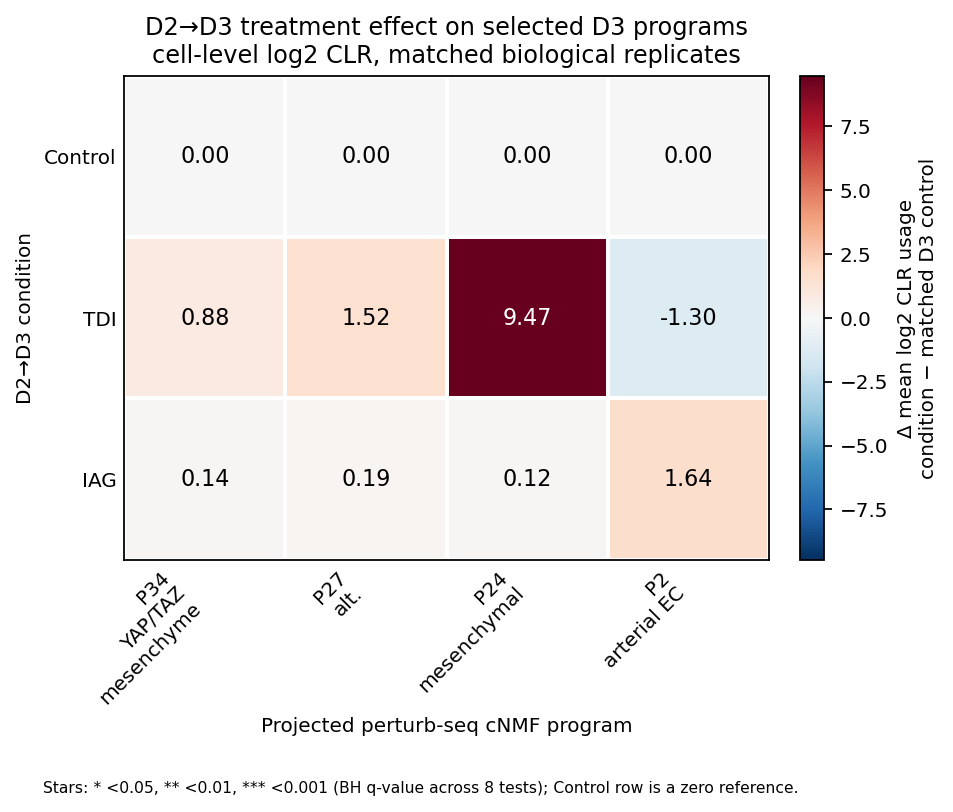

Saved: /scratch/users/edtng/20260325_Hippo_timecourse/perturbseq_cNMF_projection/D2toD3_CLR_selected_program_heatmap/D2toD3_TDI_IAG_selected_program_CLR_heatmap_control_reference_square_cells.svg


In [5]:
# Build and plot Control/TDI/IAG × P34/P27/P24/P2 heatmap.
value_matrix = pd.DataFrame(0.0, index=ROW_ORDER, columns=PROGRAMS)
p_matrix = pd.DataFrame(np.nan, index=ROW_ORDER, columns=PROGRAMS)
q_matrix = pd.DataFrame(np.nan, index=ROW_ORDER, columns=PROGRAMS)

for _, row in effects.iterrows():
    value_matrix.loc[row["row"], row["program"]] = row["mean_diff_clr"]
    p_matrix.loc[row["row"], row["program"]] = row["pvalue"]
    q_matrix.loc[row["row"], row["program"]] = row["qvalue_BH_8tests"]

value_matrix.to_csv(OUT_DIR / "D2toD3_CLR_selected_program_heatmap_matrix.tsv", sep="\t")
p_matrix.to_csv(OUT_DIR / "D2toD3_CLR_selected_program_heatmap_pvalues.tsv", sep="\t")
q_matrix.to_csv(OUT_DIR / "D2toD3_CLR_selected_program_heatmap_qvalues.tsv", sep="\t")

values = value_matrix.to_numpy(dtype=float)
vmax = np.nanmax(np.abs(values[1:, :]))
if not np.isfinite(vmax) or vmax == 0:
    vmax = 1.0
norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)

# 4 columns x 3 rows; equal aspect makes every grid cell square.
fig, ax = plt.subplots(figsize=(6.8, 5.4))
mesh = ax.pcolormesh(
    np.arange(len(PROGRAMS) + 1),
    np.arange(len(ROW_ORDER) + 1),
    values,
    cmap="RdBu_r",
    norm=norm,
    shading="flat",
    linewidth=1.0,
    edgecolors="white",
)
ax.set_aspect("equal", adjustable="box")
ax.set_xlim(0, len(PROGRAMS))
ax.set_ylim(len(ROW_ORDER), 0)
ax.set_xticks(np.arange(len(PROGRAMS)) + 0.5)
ax.set_yticks(np.arange(len(ROW_ORDER)) + 0.5)
ax.set_xticklabels([PROGRAM_LABELS[p] for p in PROGRAMS], rotation=45, ha="right")
ax.set_yticklabels(ROW_ORDER)
ax.set_xlabel("Projected perturb-seq cNMF program")
ax.set_ylabel("D2→D3 condition")
ax.set_title("D2→D3 treatment effect on selected D3 programs\ncell-level log2 CLR, matched biological replicates")
ax.tick_params(length=0)

star_matrix = q_matrix if STAR_SOURCE == "qvalue" else p_matrix
for i, row_name in enumerate(ROW_ORDER):
    for j, program in enumerate(PROGRAMS):
        val = value_matrix.loc[row_name, program]
        if row_name == "Control":
            annotation = "0.00"
        else:
            sig_value = star_matrix.loc[row_name, program]
            annotation = f"{val:.2f}{significance_stars(sig_value)}"
        # Use white text on darkest cells.
        rgba = mpl.colormaps["RdBu_r"](norm(val))
        luminance = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
        text_color = "white" if luminance < 0.42 else "black"
        ax.text(j + 0.5, i + 0.5, annotation, ha="center", va="center", color=text_color, fontsize=10)

cbar = fig.colorbar(mesh, ax=ax, fraction=0.045, pad=0.04)
cbar.set_label("Δ mean log2 CLR usage\ncondition − matched D3 control")

star_label = "BH q-value across 8 tests" if STAR_SOURCE == "qvalue" else "unadjusted paired t-test p-value"
fig.text(0.5, 0.01, f"Stars: * <0.05, ** <0.01, *** <0.001 ({star_label}); Control row is a zero reference.", ha="center", fontsize=7)
fig.subplots_adjust(left=0.18, right=0.88, bottom=0.28, top=0.84)

stem = OUT_DIR / "D2toD3_TDI_IAG_selected_program_CLR_heatmap_control_reference_square_cells"
for ext in ["svg", "pdf", "png"]:
    fig.savefig(stem.with_suffix(f".{ext}"), bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", stem.with_suffix(".svg"))

## Statistical interpretation

For every treatment × program cell, the test is a one-sample t-test of the three matched replicate CLR differences against zero. This is mathematically equivalent to a paired t-test of treated versus control sample-level CLR values. The displayed default stars use Benjamini–Hochberg adjustment across the eight non-control heatmap cells.

With only three biological replicate pairs, the test has low power. A blank star field does not imply absence of a consistent direction; inspect the saved paired-replicate table as well.